# Workbook Exercise: Credit Card Fraud Detection
**Team:** ICT110_winxClub  
**Project:** Detecting Fraudulent Financial Transactions Using Machine Learning  
**Milestones:** Task 2 (Stages B–C), Task 3 (Stage D) — November 19, 2026  
**Status:** Workbook template; results must be produced by running the actual dataset.

**Goal:** Explore and prepare the ULB credit-card dataset and compare a naive baseline with three different classifier families using cross-validation. **Do not evaluate the held-out test set in this checkpoint.**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/ColabNotebooks/ICT110_winxClub/dataset/creditcard.csv"
)

print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Display column names and data types
df.info()

# Generate descriptive statistics
df.describe()

Dataset shape: (284807, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-n

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [ ]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Duplicate rows: 1081


In [ ]:
# Count legitimate and fraudulent transactions
print(df["Class"].value_counts())

# Calculate percentages
print(df["Class"].value_counts(normalize=True) * 100)

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


## Before you begin
1. Download `creditcard.csv` from [the ULB dataset on Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) under its applicable licence and place it next to this notebook.
2. Install packages if needed: `pip install pandas numpy matplotlib seaborn scikit-learn joblib`.
3. Run cells in order. Replace **Your answer** prompts with observations from actual outputs.
4. Never fit supervised feature selection, scaling, or resampling on the full dataset before splitting or cross-validation.

**Workbook style:** numbered exercises, executable code, figures, and reflection prompts, adapted from the provided Wisconsin Diagnostic workbook. The project guideline PDF takes precedence.

---
## A. Problem Definition
### A.1 Brief Description
This is **supervised binary classification** of historical credit-card transactions: `Class = 0` (legitimate), `Class = 1` (fraud). The dataset is described as containing 284,807 transactions, including 492 frauds, from two days in September 2013. Predictors are `Time`, `Amount`, and anonymized `V1`–`V28`. The intended use is to prioritize human investigation, not automatically prove fraud.

### A.2 Problem Statement
**Question A.1.** Can transaction features identify potentially fraudulent payments for review? Who benefits and what are the costs of false alarms versus missed fraud?

**Your answer:** _Complete in your group's own words._

**Primary metric:** Average Precision (AP) from the precision–recall curve. Supporting metrics: precision, recall, F1 and confusion matrix. The constant-score naive AP benchmark should be measured on validation folds.

### A.3 Load Packages — Exercise A.2

In [ ]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve)
SEED = 42
np.random.seed(SEED)
print('Seed:', SEED)
print('Python:', sys.version.split()[0], 'pandas:', pd.__version__, 'numpy:', np.__version__, 'sklearn:', sklearn.__version__)

Seed: 42
Python: 3.13.18 pandas: 2.2.3 numpy: 2.4.6 sklearn: 1.6.1


### A.4 Load Dataset — Exercise A.3
The raw dataset is not included in this workbook. Use the actual `creditcard.csv`; no synthetic results are substituted.

In [ ]:
DATA_PATH = Path(
    "/content/drive/MyDrive/ColabNotebooks/ICT110_winxClub/dataset/creditcard.csv"
)
if not DATA_PATH.exists():
    raise FileNotFoundError('Download creditcard.csv from the ULB Kaggle dataset and place it beside this notebook.')
df = pd.read_csv(DATA_PATH)
expected = ['Time'] + [f'V{i}' for i in range(1, 29)] + ['Amount', 'Class']
assert all(c in df.columns for c in expected), 'Unexpected dataset columns; inspect the CSV.'
assert set(df['Class'].dropna().unique()).issubset({0, 1}), 'Class must be 0 or 1.'
print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


---
## B. Summarize and Analyze Data
### B.1 Descriptive Statistics
**Exercise B.1.** Inspect dataset dimensions, types, missing values and first rows.

In [ ]:
print('Shape:', df.shape)
display(df.dtypes.to_frame('dtype'))
display(df.isna().sum().to_frame('missing').query('missing > 0'))
display(df.head())

Shape: (284807, 31)


,dtype
Time,float64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


,missing


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


**Exercise B.2.** Quantify class imbalance. Why is accuracy alone misleading?

,count,percent
Class,,
0,284315,99.827251
1,492,0.172749


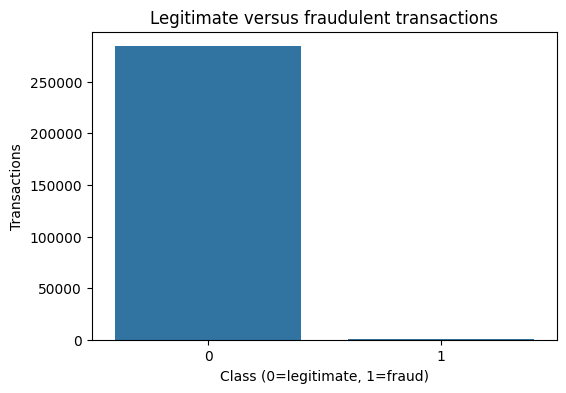

In [ ]:
class_counts = df['Class'].value_counts().sort_index()
class_pct = df['Class'].value_counts(normalize=True).sort_index().mul(100)
display(pd.DataFrame({'count': class_counts, 'percent': class_pct}))
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Class', ax=ax)
ax.set(title='Legitimate versus fraudulent transactions', xlabel='Class (0=legitimate, 1=fraud)', ylabel='Transactions')
plt.show()

**Exercise B.3.** Describe numeric features and rank the most skewed predictors.

In [ ]:
features = [c for c in expected if c != 'Class']
display(df[features].describe().T)
display(df[features].skew().abs().sort_values(ascending=False).head(10).to_frame('absolute_skew'))

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


,absolute_skew
Amount,16.977724
V28,11.192091
V8,8.521944
V23,5.875140
V2,4.624866
V17,3.844914
V21,3.592991
V1,3.280667
V7,2.553907
V5,2.425901


**Exercise B.4.** Explore correlations with the target (descriptive only; not feature selection).

In [ ]:
target_corr = df[features + ['Class']].corr(numeric_only=True)['Class'].drop('Class').sort_values()
display(pd.concat([target_corr.head(5), target_corr.tail(5)]).to_frame('correlation_with_Class'))

,correlation_with_Class
V17,-0.326481
V14,-0.302544
V12,-0.260593
V10,-0.216883
V16,-0.196539
V19,0.034783
V21,0.040413
V2,0.091289
V4,0.133447
V11,0.154876


**Question B.5.** What does the imbalance imply for AP, recall, and stratified splitting? What do skewness and extreme values suggest?

**Your answer:** _Use actual results._

### B.2 Data Visualization
**Exercise B.6 (univariate).** Plot distributions of `Amount` and `Time` (display a log-scaled Amount axis for readability).

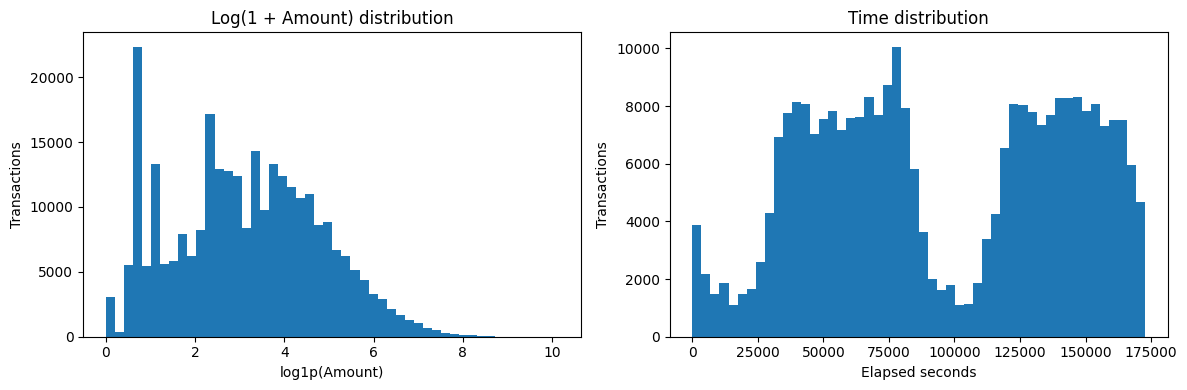

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log1p(df['Amount'].clip(lower=0)), bins=50)
axes[0].set(title='Log(1 + Amount) distribution', xlabel='log1p(Amount)', ylabel='Transactions')
axes[1].hist(df['Time'], bins=50)
axes[1].set(title='Time distribution', xlabel='Elapsed seconds', ylabel='Transactions')
plt.tight_layout(); plt.show()

**Exercise B.7 (bivariate).** Compare selected predictors by class using boxplots; avoid interpreting PCA variables as known original features.

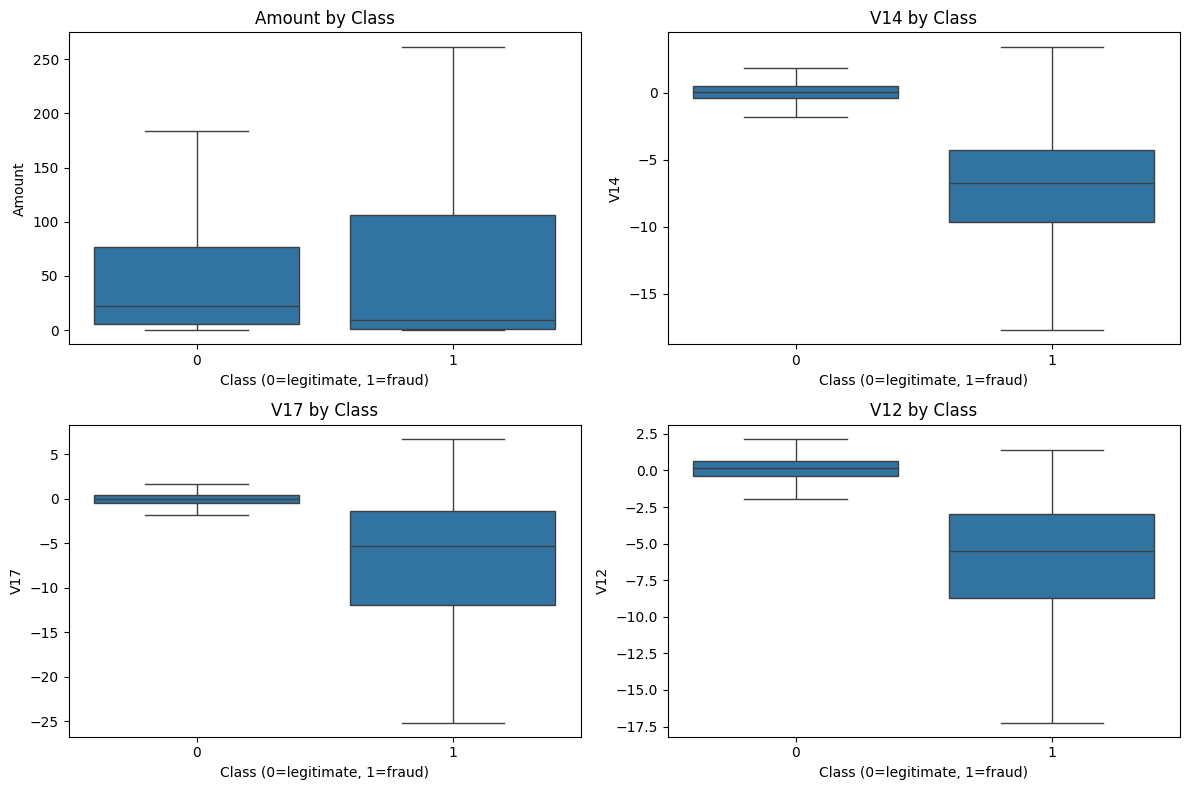

In [ ]:
plot_cols = ['Amount', 'V14', 'V17', 'V12']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, plot_cols):
    sns.boxplot(data=df, x='Class', y=col, ax=ax, showfliers=False)
    ax.set(title=f'{col} by Class', xlabel='Class (0=legitimate, 1=fraud)')
plt.tight_layout(); plt.show()

**Exercise B.8 (multivariate).** Plot correlations between predictors to investigate redundancy.

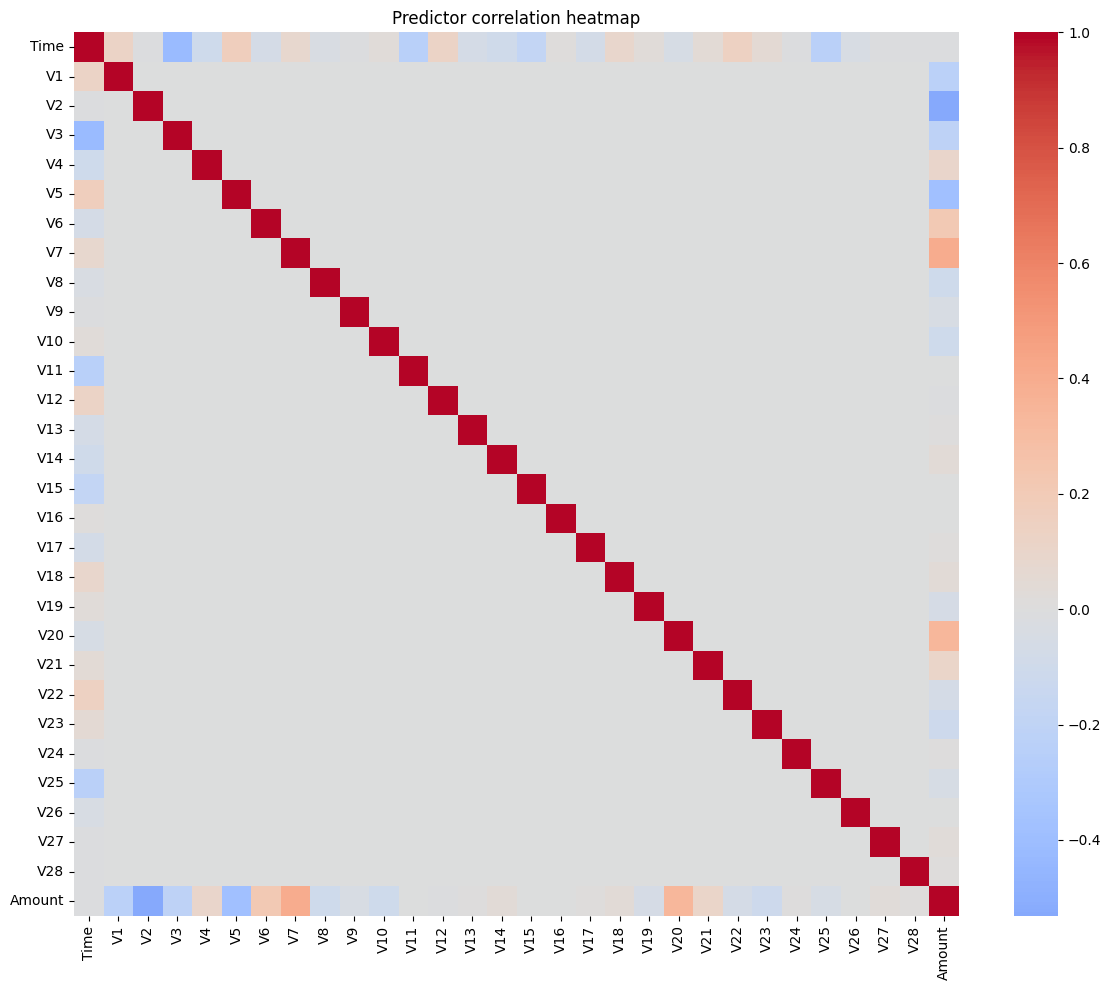

absolute_correlation
V2   Amount              0.531409
Time V3                  0.419618
V7   Amount              0.397311
V5   Amount              0.386356
V20  Amount              0.339403
Time V11                 0.247689
     V25                 0.233083
V1   Amount              0.227709
V6   Amount              0.215981
V3   Amount              0.210880

In [ ]:
corr = df[features].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, ax=ax)
ax.set_title('Predictor correlation heatmap')
plt.tight_layout(); plt.show()
pairs = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
display(pairs.head(10).to_frame('absolute_correlation'))

**Exercise B.9 (multivariate).** Scatter sample points for two anonymized variables, colored by fraud label.

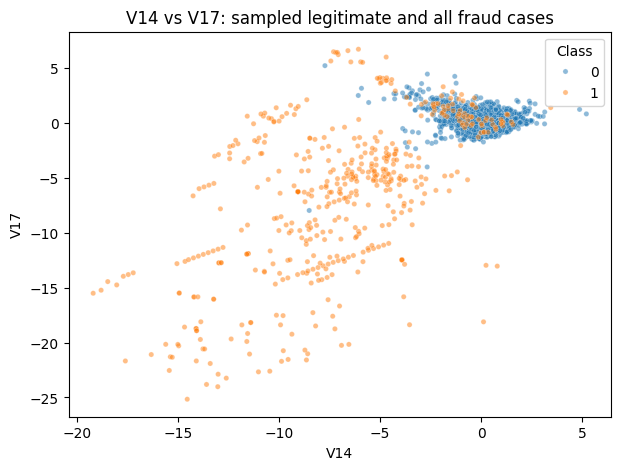

In [ ]:
sampled = pd.concat([df[df.Class == 0].sample(n=min(3000, (df.Class == 0).sum()), random_state=SEED), df[df.Class == 1]])
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=sampled, x='V14', y='V17', hue='Class', alpha=0.5, s=14, ax=ax)
ax.set_title('V14 vs V17: sampled legitimate and all fraud cases')
plt.show()

**Question B.10.** Which features seem associated with fraud? Identify two supporting figures, one surprising pattern to investigate, and any potential leakage risks. Correlation with `Class` is exploratory, not proof of causation.

**Your answer:** _Use your figures and computed values._

---
## C. Prepare Data
### C.1 Data Cleaning
**Exercise C.1.** Check missing, duplicate, non-finite and invalid records. **Do not automatically drop duplicate fraud transactions:** repeated-looking transactions may be genuine events.

In [ ]:
print('Missing values:', int(df.isna().sum().sum()))
print('Exact duplicate rows:', int(df.duplicated().sum()))
print('Negative Amount:', int((df['Amount'] < 0).sum()))
print('Negative Time:', int((df['Time'] < 0).sum()))
print('Non-finite predictor entries:', int((~np.isfinite(df[features].to_numpy(dtype=float))).sum()))

Missing values: 0
Exact duplicate rows: 1081
Negative Amount: 0
Negative Time: 0
Non-finite predictor entries: 0


**Exercise C.2.** Count IQR outliers for each numeric feature; do not assume rare fraud signals should be deleted.

In [ ]:
q1, q3 = df[features].quantile(.25), df[features].quantile(.75)
iqr = q3 - q1
outlier_counts = ((df[features] < (q1 - 1.5 * iqr)) | (df[features] > (q3 + 1.5 * iqr))).sum()
display(outlier_counts.sort_values(ascending=False).head(10).to_frame('IQR_outliers'))

,IQR_outliers
V27,39163
Amount,31904
V28,30342
V20,27770
V8,24134
V6,22965
V23,18541
V12,15348
V21,14497
V14,14149


**Question C.3.** Which issues require cleaning, and why? Will you remove duplicates or extreme values? Justify using evidence.

**Your answer:** _Do not assume all anomalies are errors._

### C.2 Split Before Learning from Data
**Exercise C.4.** Reserve a stratified 20% test set. Never inspect test performance during Tasks 2–3.

In [ ]:
X = df[features].copy()
y = df['Class'].astype(int)
# Explicit invalid-value cleanup; replacement rules are fixed, not learned.
X = X.replace([np.inf, -np.inf], np.nan)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print('Train:', X_train.shape, 'Fraud:', int(y_train.sum()))
print('Held-out test:', X_test.shape, '(labels reserved; no evaluation until Task 4)')

Train: (227845, 30) Fraud: 394
Held-out test: (56962, 30) (labels reserved; no evaluation until Task 4)


### C.3 Feature Selection and Transforms
**Exercise C.5.** Investigate redundancy using **training features only**. No supervised feature selection is finalized before cross-validation.

In [ ]:
train_corr = X_train.corr(numeric_only=True).abs()
redundant_pairs = train_corr.where(np.triu(np.ones(train_corr.shape), 1).astype(bool)).stack()
display(redundant_pairs[redundant_pairs > 0.95].sort_values(ascending=False).to_frame('absolute_correlation'))
selected_features = list(X_train.columns)  # conservative starting point; no leakage
print('Initial selected features:', len(selected_features))

,,absolute_correlation


Initial selected features: 30


**Exercise C.6.** Define preprocessing pipelines. Logistic Regression needs scaling; Random Forest and histogram gradient boosting generally do not. Any learned imputation/scaling must be fitted inside each CV fold.

In [ ]:
scaled_prep = Pipeline([('imputer', SimpleImputer(strategy='median')),
                        ('scaler', StandardScaler())])
tree_prep = Pipeline([('imputer', SimpleImputer(strategy='median'))])
print('Scaled preparation:', scaled_prep)
print('Tree preparation:', tree_prep)

Scaled preparation: Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])
Tree preparation: Pipeline(steps=[('imputer', SimpleImputer(strategy='median'))])


**Question C.7.** Explain the 80/20 stratified split, leakage prevention, feature choices, and why each transform is appropriate. Can every feature be available at prediction time? Consider whether `Time` is meaningful in a real-time system.

**Your answer:** _Complete after inspection._

**Note:** A chronological split was proposed in Task 1 for deployment realism; it is not used in this initial stratified comparison and should be considered as a later sensitivity check.

---
## D. Evaluate Algorithm
Use the same **stratified 5-fold CV** splits and **Average Precision** for all models. Report fold-to-fold variability. A constant prior-probability dummy model is the naive baseline. **No held-out test evaluation here.**

### D.1 Candidate Algorithms
- **DummyClassifier (`prior`)** — naive constant-score baseline.
- **Logistic Regression** — linear probabilistic classifier; scaling helps and coefficients are relatively interpretable.
- **Random Forest** — bagged decision trees; captures nonlinear interactions, but can be costly.
- **HistGradientBoosting** — boosted trees; a third algorithm family, handles nonlinear structure and may need tuning.

**Exercise D.1.** Build candidate pipelines with consistent training-only preprocessing.

In [ ]:
models = {
    'Dummy prior': Pipeline([('prep', tree_prep), ('model', DummyClassifier(strategy='prior'))]),
    'Logistic Regression': Pipeline([('prep', scaled_prep), ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED))]),
    'Random Forest': Pipeline([('prep', tree_prep), ('model', RandomForestClassifier(n_estimators=100, min_samples_leaf=2, class_weight='balanced_subsample', n_jobs=1, random_state=SEED))]),
    'HistGradientBoosting': Pipeline([('prep', tree_prep), ('model', HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=SEED))])
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print('Candidates:', list(models))

Candidates: ['Dummy prior', 'Logistic Regression', 'Random Forest', 'HistGradientBoosting']


**Exercise D.2.** Compare the baseline and three model families on identical folds, using AP. This may take several minutes on a typical laptop.

In [ ]:
rows = []
fold_results = {}
for name, model in models.items():
    scores = cross_validate(model, X_train[selected_features], y_train, cv=cv,
                            scoring={'ap': 'average_precision', 'roc_auc': 'roc_auc'},
                            n_jobs=1, error_score='raise')
    fold_results[name] = scores['test_ap']
    rows.append({'model': name, 'AP_mean': scores['test_ap'].mean(),
                 'AP_std': scores['test_ap'].std(ddof=1),
                 'ROC_AUC_mean': scores['test_roc_auc'].mean()})
comparison = pd.DataFrame(rows).sort_values('AP_mean', ascending=False)
display(comparison)

,model,AP_mean,AP_std,ROC_AUC_mean
2,Random Forest,0.838043,0.022779,0.952463
1,Logistic Regression,0.757136,0.058245,0.982484
3,HistGradientBoosting,0.645155,0.062591,0.811082
0,Dummy prior,0.001729,0.000010,0.500000


**Exercise D.3.** Compare AP variability across folds and the gap from the naive baseline.

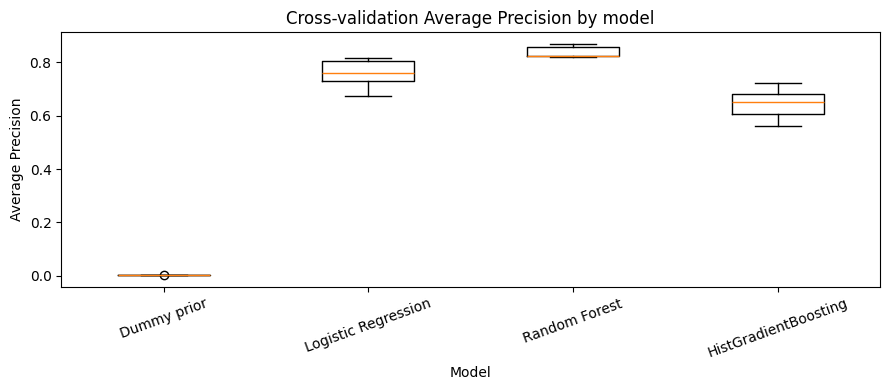

,model,AP_mean,AP_std,ROC_AUC_mean,AP_gain_over_dummy
2,Random Forest,0.838043,0.022779,0.952463,0.836314
1,Logistic Regression,0.757136,0.058245,0.982484,0.755407
3,HistGradientBoosting,0.645155,0.062591,0.811082,0.643426
0,Dummy prior,0.001729,0.000010,0.500000,0.000000


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot(list(fold_results.values()), tick_labels=list(fold_results.keys()))
ax.set(title='Cross-validation Average Precision by model', ylabel='Average Precision', xlabel='Model')
ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()
base_ap = comparison.loc[comparison.model == 'Dummy prior', 'AP_mean'].iloc[0]
comparison['AP_gain_over_dummy'] = comparison['AP_mean'] - base_ap
display(comparison)

**Question D.4.** Which models outperform the baseline? Are gains large relative to standard deviation across folds? Explain each algorithm's assumptions, speed, interpretability and limitations.

**Your answer:** _Use measured values._

### D.2 Error Analysis on Training Data Only
**Exercise D.5.** Choose the highest-AP learned model from CV. Produce **out-of-fold** predictions on training data to inspect errors. Threshold 0.5 is illustrative, not tuned.

Provisional shortlist: Random Forest
Out-of-fold AP: 0.8366081039504961
Precision: 0.9276729559748428
Recall: 0.748730964467005
F1: 0.8286516853932584


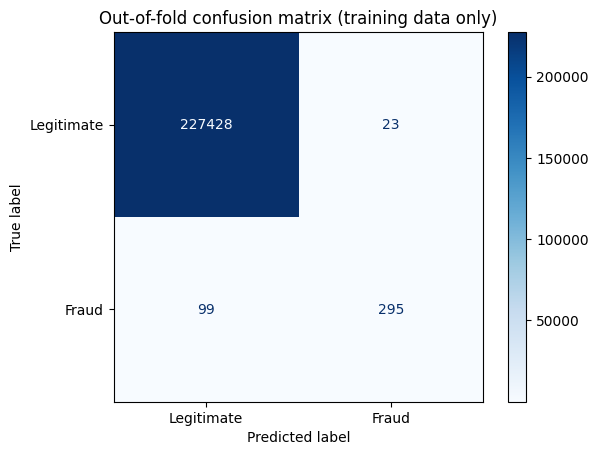

In [ ]:
learned = comparison[comparison.model != 'Dummy prior']
shortlist_name = learned.iloc[0]['model']
print('Provisional shortlist:', shortlist_name)
# This second CV pass produces out-of-fold predictions; test data is never used.
oof_prob = cross_val_predict(models[shortlist_name], X_train[selected_features], y_train,
                             cv=cv, method='predict_proba', n_jobs=1)[:, 1]
oof_pred = (oof_prob >= 0.5).astype(int)
print('Out-of-fold AP:', average_precision_score(y_train, oof_prob))
print('Precision:', precision_score(y_train, oof_pred, zero_division=0))
print('Recall:', recall_score(y_train, oof_pred, zero_division=0))
print('F1:', f1_score(y_train, oof_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_train, oof_pred, display_labels=['Legitimate', 'Fraud'], cmap='Blues')
plt.title('Out-of-fold confusion matrix (training data only)')
plt.show()

**Exercise D.6.** Visualize the precision–recall curve for the provisional model (out-of-fold training predictions).

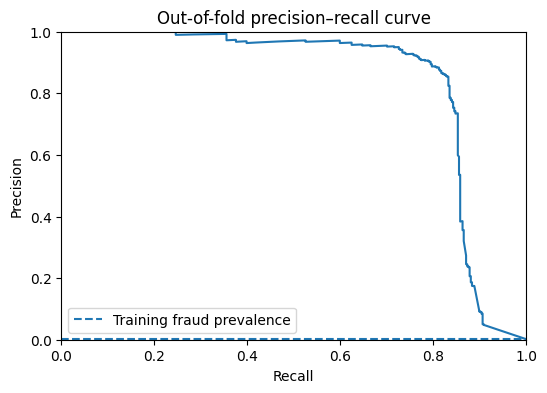

In [ ]:
precision, recall, thresholds = precision_recall_curve(y_train, oof_prob)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(recall, precision)
ax.axhline(y_train.mean(), linestyle='--', label='Training fraud prevalence')
ax.set(title='Out-of-fold precision–recall curve', xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1))
ax.legend(); plt.show()

**Question D.7.** How many false positives and false negatives are shown? Why does this matter to fraud investigators? What is your provisional shortlist and why?

**Your answer:** _Use actual counts. Do not claim this is final test performance._

---
## Task 2 and Task 3 Checkpoint Summary
Complete this section after running the notebook:

1. **Stage B findings:** Dataset shape, missing/duplicate counts, fraud prevalence, two informative plots, redundancy and leakage concerns.
2. **Stage C decisions:** Cleaning rationale, split method, transformations, feature availability and pipeline safeguards.
3. **Stage D results:** Table of 5-fold AP mean ± SD for dummy and three candidates; variability plot, shortlist and out-of-fold confusion matrix.
4. **Limitations:** Historical two-day dataset, anonymized PCA variables, limited operational interpretability, and no final test result yet.

**Your group’s summary:** _Write concise, evidence-based conclusions here._

## E. Improve Accuracy — Reserved for Task 4 (December 3, 2026)
Hyperparameter search, feature engineering experiments, and **one final held-out test evaluation** belong to Task 4. Do not use the held-out test set in this notebook checkpoint.

## Reflection Questions
1. Why is accuracy misleading for 0.172% fraud prevalence?
2. Why must imputation and scaling be fitted within CV folds?
3. Why is AP appropriate, and what do false positives and false negatives cost?
4. Which candidate model should be investigated next and why?

## References and Reproducibility
- Machine Learning Group, Université Libre de Bruxelles, *Credit Card Fraud Detection*, Kaggle: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
- Saito and Rehmsmeier (2015), *The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets*: https://doi.org/10.1371/journal.pone.0118432
- Record the Python and package versions printed in A.3 and the fixed seed (42).
- Declare any AI assistance in the final report appendix per instructor guidance.
